In [1]:
# Data libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import Lasso
from matplotlib.patches import Patch
import matplotlib.dates as mdates


# Used in helper functions
labels = ["avg", "min", "max"]

# Cleaning choice
tidal_threshold = 1.5  # median daily range (m) above this = tide gauge

# Time split
cutoff_final, end_final = "2026-08-31", "2026-11-30"  # final test 
cv_years = [2022, 2023, 2024, 2025]                   # one fold per autumn
cutoff = pd.Timestamp(cutoff_final)                   # used by clean_error

# Features, target 
target = "z"
season_cols = ["sin_doy", "cos_doy"]

# model arguments
seed = 0
cv_results = []


Introduction

Goal: predict the daily average water level at each station for 1 September – 30 November 2026, training only on data up to 31 August 2026.
Task interpretation (reading B): one-day-ahead prediction. The level on day $t$ is predicted from observations up to day $t-1$, so the September–November observations are used as inputs as they arrive.
Alternative interpretation (reading A): forecast the whole autumn using only data up to 31 August. Every model then plateaued at CV $\text{RMSE}_z \approx 1.08$, about the same as the seasonal baseline, so the calendar features alone carry little information.
The test data available covers 1 September – 8 October 2026 (38 days).

Data cleaning

Sentinel error codes are masked cell by cell, so only the bad value becomes NaN, not the whole row.
Outliers: per station, below $Q_1 - 20\,\text{IQR}$ or above $Q_3 + 20\,\text{IQR}$, with quartiles from training data only. They are removed from the training period only, so the test set is evaluated as recorded.
Stations: 392 series → tide gauges removed (median daily range above 1.5 m) → stations with less than 3 years of training data removed → 361 stations. Quote the exact numbers from .attrs.

Target and features

Target: the standardised level $z_{s,t} = (y_{s,t} - \mu_s)/\sigma_s$, with $\mu_s, \sigma_s$ from training data only. This lets one model be pooled across rivers of very different sizes.
Seasonality: $(\sin\theta, \cos\theta)$ with $\theta = 2\pi\,\text{doy}/365.25$, where doy is the day of the year. This makes 31 December and 1 January neighbours.
Climatology (clim): the mean of $z$ for each station and calendar month, from training data only (Pappenberger et al., 2015, Table 3).
Lags (reading B): $\text{lag1} = z_{t-1}$, $\text{trend} = z_{t-1} - z_{t-2}$, and $\text{lag7}$ = the mean of $z_{t-1},\dots,z_{t-7}$ (at least 4 observed) (Hyndman and Athanasopoulos, 2018, Ch. 8; Wang and Wang, 2020, Sect. 3.1).
Latitude and longitude were tested and dropped: their coefficients were $\approx 0$, because standardisation removes each station's own level, and coordinates are constant within a station.

Validation

Rolling-origin cross-validation with 4 folds (2022–2025): fit on data up to 31 August of year $Y$, validate on 1 September – 30 November of $Y$.
Standard random $K$-fold was not used, because it would train on days after the validation days (leakage).
The station filter, $\mu_s$, $\sigma_s$ and clim are recomputed inside each fold.
Metric: $\text{RMSE}_z$, given as the mean ± sd over folds, plus a per-fold paired comparison.
Kernel models are fitted on random subsamples (3000 rows for KRR, 2000 for the sparse kernel), because the $N \times N$ kernel matrix is computationally infeasible for $N \approx 10^6$.

Baseline

Seasonal linear regression on $(\sin\theta, \cos\theta)$: $\hat z = 0.032 + 0.643\cos\theta - 0.040\sin\theta \approx 0.64\cos(\theta + 0.062)$. That is a yearly cycle with amplitude $0.64\sigma$, peaking around late December. Check: these coefficients come from the old 372-station pipeline, so print them again from the 361-station fit.

Models explored (brief)

Ridge, Lasso and Elastic Net: tuning $\alpha$ had almost no effect, because with $n \approx 10^6$ the data term dominates the penalty. A strong Lasso/EN penalty sets every weight to 0 (CV 1.131).
Polynomial regression: CV picks degree 1, and degrees 2 and 3 are worse. The squared and cubed lag terms extrapolate badly at extreme (storm) values.
Kernel ridge (RBF): the best setting is the smallest $\gamma$. As $\gamma \to 0$ the RBF kernel behaves almost linearly, so KRR converges to the linear AR.
Sparse kernel machine: best $(\alpha, \gamma) = (10^{-4}, 0.03)$, CV 0.694. A larger $\gamma$ keeps more centroids and does worse on CV (overfitting).
Final model: linear AR, with the best CV (0.674 ± 0.149) and the simplest form.

Discussion (not a limitation)

Weekly climatology was tested and performed worse than monthly (CV 1.103 vs 1.080 in reading A). There are too few observations per station-week, so the estimates are noisy: a bias–variance trade-off.

In [2]:
def reshape_long(avg_df, min_df, max_df, loc_df, start = "2017-04-01", drop_tidal = True):
    """
    Convert the df from Wide -> long, drop tidal series, attach coordinates
    Input:
    - avg_df, min_df, max_df: Average, Minimum and Maximum df
    - loc_df: locations df
    - start: observations before this date will be removed
    - drop_tidal: boolean value, should tidal-level stations be removed
    Returns:
    - river long df: df with one row per station per day and columns
    """
    data = [avg_df, min_df, max_df]
    column = ["County", "Station_Name", "Observation_ID", "date"]
    long_df = {}

    for df, lab in zip(data, labels):
        if drop_tidal:
            df = df[~df["Observation_ID"].str.contains("tidal-level", na = False)]

        long_df[lab] = df.melt(id_vars = column[0:3], var_name = "date", value_name = lab)
        long_df[lab]["date"] = pd.to_datetime(long_df[lab]["date"], format = "%d/%m/%Y")
        long_df[lab] = long_df[lab][long_df[lab]["date"] >= start]

    river_long = (long_df["avg"]
                 .merge(long_df["min"], on = column, how = "left")
                 .merge(long_df["max"], on = column, how = "left"))

    n_before = len(river_long)  # row count before attaching locations, if it changes a station is duplicated in loc_df
    river_long = river_long.merge(loc_df, on = column[0:3], how = "left")
    assert len(river_long) == n_before, "location merge duplicated rows"

    # a station name that didnt match gives NaN coordinates
    print(f"Number of missing latitude: {river_long['Latitude'].isna().sum()}")
    print(f"Number of missing longitude: {river_long['Longitude'].isna().sum()}")

    for col in column[0:3]:
        river_long[col] = river_long[col].astype("category")

    return river_long

def clean_error(df, k = 20):
    """
    Cleaning: sentinels (cell-wise), outliers (train only), order check
    Input:
    - df: long data frame that contains Observation_ID, date, avg, min, max
    - k: number of IQRs beyond Q1/Q3 at which a value is an outlier
    Returns:
    - df2 : a copy of the df with the bad values replaced by NaN values
    """
    
    df2 = df.copy()

    large_vals = df2[labels].isin([99999.999, -999999.999, -99]) | (df2[labels].abs() >= 9999)
    # cell by cell, only the bad value becomes NaN not the whole row
    df2[labels] = df2[labels].where(~large_vals, np.nan)

    for lab in labels:
        # quartiles from training dates only (no leakage)
        train_val = df2[lab].where(df2["date"] <= cutoff)
        per_sta = train_val.groupby(df2["Observation_ID"], observed = True)

        q1 = per_sta.transform(lambda s: s.quantile(0.25))
        q3 = per_sta.transform(lambda s: s.quantile(0.75))
        sd = per_sta.transform("std")

        iqr = (q3 - q1).where(q3 - q1 > 0, sd)  # if iqr = 0 we use std
        outlier = ((df2[lab] > q3 + k * iqr) | (df2[lab] < q1 - k * iqr))

        df2.attrs[f"sentinel_{lab}"] = int(large_vals[lab].sum())
        df2.attrs[f"outliers_{lab}"] = int(outlier.sum())

        # count flagged test values, but only remove the training ones
        df2.attrs[f"outliers_{lab}_test"] = int((outlier & (df2["date"] > cutoff)).sum())
        df2.loc[outlier & (df2["date"] <= cutoff), lab] = np.nan

    bad = (df2["min"] > df2["avg"]) | (df2["avg"] > df2["max"])
    df2.attrs["order_violations"] = int(bad.sum())
    df2.loc[bad, labels] = np.nan

    return df2

def drop_ids(df, min_years = 3, cutoff = cutoff_final, threshold = tidal_threshold):
    
    """
    INPUT:
    - df (long+cleaned dataframe): contains Observation_ID, date, avg, min, max
    - min_years: minimum number of years of non missing avg data a station needs to be kept
    - cutoff: last day of training period
    - threshold: max median daily range 
    
    OUTPUT:
    - keep_df: copy of df containing only stations we keep
    """

    cutoff = pd.Timestamp(cutoff) 

    is_train = df["date"] <= cutoff
    train_obs = df["avg"].notna() & is_train
    years = train_obs.groupby(df["Observation_ID"], observed = True).sum() / 365.25
    
    median_range = (df["max"] - df["min"]).where(is_train).groupby(df["Observation_ID"], observed = True).median()

    keep_ids = years[(years >= min_years) & (median_range <= threshold)].index

    keep_df = df[df["Observation_ID"].isin(keep_ids)].copy()
    keep_df.attrs["dropped_short"] = int((years < min_years).sum())
    keep_df.attrs["dropped_tidal"] = int((median_range > threshold).sum())
    keep_df.attrs["kept_ids"]      = int(len(keep_ids))

    return keep_df

def add_features(df, cutoff):
    
    """
    INPUT:
    - df: long df containing Observation_ID, date, avg, min, max
    - cutoff: last training date ("2025-08-31" for validation, "2026-08-31" for final test)

    OUTPUT:
    - df2: copy of df with columns added (station stats use training rows only):
        * sta_mean, sta_std: station's mean and stdev of avg level
        * z: standardized level (target)
        * daily_range: station's median (max - min), divided by its IQR of avg
        * sin_doy, cos_doy: day-of-year waves
    """
    
    df2 = df.copy()  
    cutoff = pd.Timestamp(cutoff)
    is_train = df2["date"] <= cutoff 

    train_val = df2["avg"].where(is_train)                 
    per_sta = train_val.groupby(df2["Observation_ID"], observed=True)

    df2["sta_mean"] = per_sta.transform("mean")
    df2["sta_std"]  = per_sta.transform("std").replace(0, np.nan)   # stdev 0 → NaN (avoid ±∞)
    df2["z"] = (df2["avg"] - df2["sta_mean"]) / df2["sta_std"]

    rng_train = (df2["max"] - df2["min"]).where(is_train)
    q1 = per_sta.transform(lambda s: s.quantile(0.25))
    q3 = per_sta.transform(lambda s: s.quantile(0.75))
    iqr = (q3 - q1).replace(0, np.nan)  # IQR 0 → NaN
    df2["daily_range"] = rng_train.groupby(df2["Observation_ID"], observed=True).transform("median") / iqr

    theta = 2 * np.pi * df2["date"].dt.dayofyear / 365.25
    df2["sin_doy"],  df2["cos_doy"]  = np.sin(theta),     np.cos(theta)      
    
    return df2

def get_coefs(m, plot = False, feature_names = None, figsize = (5,5), figtitle = None, intercept = True):
    """Returns model coefficients in a data frame for a fitted linear model."""
    w = np.concatenate(([m[-1].intercept_] if isinstance(m, sklearn.pipeline.Pipeline) else [m.intercept_],
                            m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_))
    if feature_names is None:
        feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_
    feature_names = np.concatenate((['intercept'], feature_names))
    w_df = pd.DataFrame({'feature': feature_names, 'coef': w}).sort_values("coef", ascending=False)

    if plot:
        if not intercept:
            w_df = w_df[w_df['feature'] != 'intercept']
        plt.figure(figsize=figsize)
        plt.barh(w_df['feature'], w_df['coef'])
        plt.ylabel('Features')
        plt.xlabel('Coefficient Value')
        plt.axvline(x=0, color=".5")
        if figtitle is not None:
            plt.title(figtitle)
        plt.grid()
        plt.show()

    return w_df


In [3]:

def make_fold_clim(df, year):
    """
    Build one rolling-origin fold for reading A (forecast from 31 Aug, no lags).
    Input:
    - df: cleaned long df (river_long2, no station filter yet)
    - year: fold year; fit = up to 31 Aug of year, validate = 1 Sep – 30 Nov of year
    Returns:
    - fit, val: rows with target z and clim observed
    """
    c = pd.Timestamp(f"{year}-08-31")       # last training day
    v_end = pd.Timestamp(f"{year}-11-30")   # last validation day

    # station filter, mu_s, sigma_s from this fold's training period only
    df_k = drop_ids(df, min_years = 3, cutoff = c)
    feat = add_features(df_k, cutoff = c)
    feat["month"] = feat["date"].dt.month

    # climatology: station x month mean of z, from training rows only
    fit = feat[feat["date"] <= c]
    clim = fit.groupby(["Observation_ID", "month"], observed = True)["z"].mean().rename("clim")
    feat = feat.merge(clim, on = ["Observation_ID", "month"], how = "left")

    # split by date, drop rows with a missing target or clim
    fit = feat[feat["date"] <= c]
    val = feat[(feat["date"] > c) & (feat["date"] <= v_end)]
    return fit.dropna(subset = ["z", "clim"]), val.dropna(subset = ["z", "clim"])


def cv_score(model, df, years, features, target = "z", n_sub = None, fold_fn = make_fold_clim):
    """
    Cross-validation score (any model, any fold builder, optional subsample)
    Returns the RMSE on each validation autumn.
    - n_sub: train on a random subsample of this size (kernel models)
    - fold_fn: make_fold_clim
    """
    scores = np.zeros(len(years))
    for i, y in enumerate(years):
        fit, val = fold_fn(df, y)
        if n_sub is not None:
            fit = fit.sample(n = n_sub, random_state = 0)
        model.fit(fit[features], fit[target])
        pred = model.predict(val[features])
        scores[i] = root_mean_squared_error(val[target], pred)
    return scores

class RBFFeatures(BaseEstimator, TransformerMixin):
    """ Sparse kernel machine: training inputs as centroids (lecture notes)
    phi(x) = (k(x, x_1), ..., k(x, x_N)) with the training inputs as centroids."""
    def __init__(self, gamma = 1.0):
        self.gamma = gamma

    def fit(self, X, y = None):
        self.centres_ = np.asarray(X)
        return self

    def transform(self, X):
        return rbf_kernel(np.asarray(X), self.centres_, gamma = self.gamma)


def score(name, pred_z, y_true, df):

    """
    INPUT:
    - name: model name (for the results table)
    - pred_z: predicted z
    - y_true: true z
    - df: matching rows (needs sta_mean, sta_std, avg), e.g. final_df.loc[X_test.index]

    OUTPUT:
    - dict with RMSE (z), RMSE (m), MAE (m)
    """

    pred_m = pred_z * df["sta_std"] + df["sta_mean"]    # back to metres

    return {"model":    name,
            "RMSE (z)": root_mean_squared_error(y_true, pred_z),
            "RMSE (m)": root_mean_squared_error(df["avg"], pred_m),
            "MAE (m)":  mean_absolute_error(df["avg"], pred_m)}

def add_cv(name, scores, param = None):
    cv_results.append({"model": name, 
                       "param": param,
                       "cv_mean": scores.mean(), 
                       "cv_sd": scores.std(ddof = 1)})

In [4]:
river_avg = pd.read_csv("avg_river_levels.csv")
river_min = pd.read_csv("min_river_levels.csv")
river_max = pd.read_csv("max_river_levels.csv")
river_location = pd.read_csv("monitoring_locations.csv")

river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_long2 = clean_error(river_long)
river_long3 = drop_ids(river_long2)

feats = ["sin_doy", "cos_doy", "clim"]

folds_A = {}
for y in cv_years:
    folds_A[y] = make_fold_clim(river_long2, y)

def fold_A(df, y):
    return folds_A[y]

river_long2.attrs, river_long3.attrs

Number of missing latitude: 0
Number of missing longitude: 0


({'sentinel_avg': 76,
  'outliers_avg': 112,
  'outliers_avg_test': 1,
  'sentinel_min': 32,
  'outliers_min': 179,
  'outliers_min_test': 5,
  'sentinel_max': 47,
  'outliers_max': 145,
  'outliers_max_test': 0,
  'order_violations': 0},
 {'sentinel_avg': 76,
  'outliers_avg': 112,
  'outliers_avg_test': 1,
  'sentinel_min': 32,
  'outliers_min': 179,
  'outliers_min_test': 5,
  'sentinel_max': 47,
  'outliers_max': 145,
  'outliers_max_test': 0,
  'order_violations': 0,
  'dropped_short': 8,
  'dropped_tidal': 11,
  'kept_ids': 361})

In [5]:
# Here, we construct our baseline model for the regression
base = cv_score(LinearRegression(), river_long2, cv_years, ["sin_doy", "cos_doy"], fold_fn = fold_A)
base_cv_score = base.mean()
add_cv("Baseline model", base, param = None)
base_cv_score

1.08396743937463

In [6]:
# The first model, linear regression 
linear_regression = LinearRegression()
lr_score = cv_score(linear_regression, river_long2, cv_years, feats, fold_fn = fold_A)
lr_score_score = lr_score.mean()
add_cv("Linear Regression", lr_score, param = None)
lr_score_score

1.0761620143436592

In [7]:
# Now, we try Ridge, Lasso and Elastic Net Regressions
alphas = np.logspace(-4, 3, 8)
for a in alphas:
    for name, reg in [("Ridge", Ridge(alpha = a)),
                      ("Lasso", Lasso(alpha = a)),
                      ("Elastic net", ElasticNet(alpha = a, l1_ratio = 0.5))]:
        
        model  = make_pipeline(StandardScaler(), reg)
        scores = cv_score(model, river_long2, cv_years, features = feats, fold_fn = fold_A)    
        add_cv(name, scores, param = a)
res = pd.DataFrame(cv_results)
res

,model,param,cv_mean,cv_sd
0,Baseline model,NaN,1.083967,0.180352
1,Linear Regression,NaN,1.076162,0.171901
2,Ridge,0.0001,1.076162,0.171901
3,Lasso,0.0001,1.076146,0.171944
4,Elastic net,0.0001,1.076147,0.171924
5,Ridge,0.0010,1.076162,0.171901
6,Lasso,0.0010,1.076064,0.172348
7,Elastic net,0.0010,1.076064,0.172151
8,Ridge,0.0100,1.076162,0.171901
9,Lasso,0.0100,1.075883,0.174069


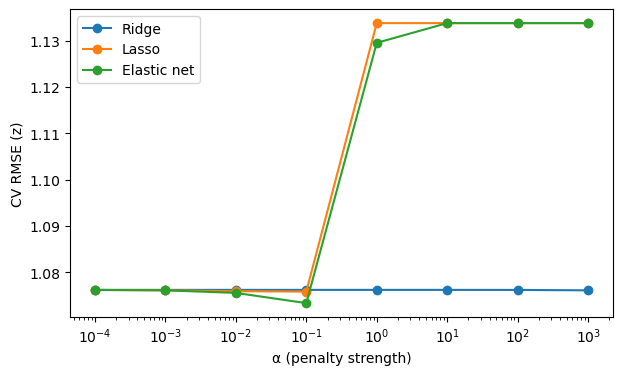

In [8]:
fig, ax = plt.subplots(figsize = (7, 4))

for name in ["Ridge", "Lasso", "Elastic net"]:
    r = res[res["model"] == name]
    ax.plot(r["param"], r["cv_mean"], marker = "o", label = name)
    
ax.set_xscale("log"); ax.set_xlabel("α (penalty strength)"); ax.set_ylabel("CV RMSE (z)")
ax.legend(); plt.show()

In [9]:
# Now, we try polynomial regression with different polynomial degrees
poly_scores = {}
degrees = [1, 2, 3]

for d in degrees:
    model = make_pipeline(StandardScaler(),
                          PolynomialFeatures(degree = d, include_bias = False), 
                          LinearRegression())
    poly_scores[d] = cv_score(model, river_long2, cv_years, features = feats, fold_fn = fold_A)
    add_cv("Polynomial", poly_scores[d], param = d)

res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("Polynomial")]

,model,param,cv_mean,cv_sd
26,Polynomial,1.0,1.076162,0.171901
27,Polynomial,2.0,1.077765,0.172618
28,Polynomial,3.0,1.076757,0.168962


In [10]:
poly_scores_ridge = {}
for d in degrees:
    for a in [1, 100, 1e4]:
        model = make_pipeline(StandardScaler(),
                                  PolynomialFeatures(degree = d, include_bias = False), 
                                  Ridge(alpha = a))
        poly_scores_ridge[a, d] = cv_score(model, river_long2, cv_years, features = feats, fold_fn = fold_A)
        add_cv("Polynomial+Ridge", poly_scores_ridge[a, d], param = (a, d))

res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("Polynomial+Ridge")]

,model,param,cv_mean,cv_sd
29,Polynomial+Ridge,"(1, 1)",1.076162,0.171901
30,Polynomial+Ridge,"(100, 1)",1.076152,0.171906
31,Polynomial+Ridge,"(10000.0, 1)",1.075321,0.172449
32,Polynomial+Ridge,"(1, 2)",1.077765,0.172618
33,Polynomial+Ridge,"(100, 2)",1.077754,0.172621
34,Polynomial+Ridge,"(10000.0, 2)",1.076901,0.173031
35,Polynomial+Ridge,"(1, 3)",1.076757,0.168962
36,Polynomial+Ridge,"(100, 3)",1.076761,0.168973
37,Polynomial+Ridge,"(10000.0, 3)",1.076762,0.169368


In [21]:
krr_scores = {}
for g in [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]:
    for a in [0.01, 0.1, 1, 10]:
        krr_A = make_pipeline(StandardScaler(),
                      KernelRidge(kernel = "rbf", alpha = a, gamma = g))
        krr_scores[a, g] = cv_score(krr_A, river_long2, cv_years, feats, n_sub = 3000, fold_fn = fold_A)
        add_cv("KernelRidge", krr_scores[a, g], param=(a, g))


res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("KernelRidge")]

,model,param,cv_mean,cv_sd
38,KernelRidge,"(0.01, 0.001)",1.071743,0.177008
39,KernelRidge,"(0.1, 0.001)",1.071063,0.176202
40,KernelRidge,"(1, 0.001)",1.068718,0.183036
41,KernelRidge,"(0.01, 0.003)",1.074445,0.177571
42,KernelRidge,"(0.1, 0.003)",1.071374,0.177166
43,KernelRidge,"(1, 0.003)",1.069436,0.178299
44,KernelRidge,"(0.01, 0.01)",1.077300,0.178108
45,KernelRidge,"(0.1, 0.01)",1.074476,0.177694
46,KernelRidge,"(1, 0.01)",1.070521,0.177938
47,KernelRidge,"(0.01, 0.03)",1.078315,0.178734


In [22]:
sk_scores = {}
for g in [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]:
    for a in [1e-5, 1e-4, 1e-3, 1e-2]:
        sk_pipe_A = make_pipeline(StandardScaler(),
                                  RBFFeatures(gamma = g),
                                  Lasso(alpha = a, max_iter = 5000, selection="random", tol=1e-3))

        sk_scores[a, g] = cv_score(sk_pipe_A, river_long2, cv_years, feats, n_sub = 2000, fold_fn = fold_A)
        add_cv("SparseKernelMachine", sk_scores[a, g], param=(a, g))
        print(a, g, "centroids kept:", (sk_pipe_A[-1].coef_ != 0).sum())
        
res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("SparseKernelMachine")]

1e-05 0.0003 centroids kept: 8
0.0001 0.0003 centroids kept: 6
0.001 0.0003 centroids kept: 1
0.01 0.0003 centroids kept: 0
1e-05 0.001 centroids kept: 13
0.0001 0.001 centroids kept: 7
0.001 0.001 centroids kept: 4
0.01 0.001 centroids kept: 0
1e-05 0.003 centroids kept: 17
0.0001 0.003 centroids kept: 9
0.001 0.003 centroids kept: 4
0.01 0.003 centroids kept: 1


c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.522e+01, tolerance: 2.059e+00
  model = cd_fast.enet_coordinate_descent(


1e-05 0.01 centroids kept: 30
0.0001 0.01 centroids kept: 10
0.001 0.01 centroids kept: 7
0.01 0.01 centroids kept: 3


c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.344e+01, tolerance: 2.059e+00
  model = cd_fast.enet_coordinate_descent(
c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.207e+01, tolerance: 1.971e+00
  model = cd_fast.enet_coordinate_descent(
c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation.

1e-05 0.03 centroids kept: 149
0.0001 0.03 centroids kept: 28
0.001 0.03 centroids kept: 8
0.01 0.03 centroids kept: 5


c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.414e+02, tolerance: 2.059e+00
  model = cd_fast.enet_coordinate_descent(
c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.623e+02, tolerance: 1.971e+00
  model = cd_fast.enet_coordinate_descent(
c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation.

1e-05 0.1 centroids kept: 416


c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.467e+01, tolerance: 2.059e+00
  model = cd_fast.enet_coordinate_descent(


0.0001 0.1 centroids kept: 23
0.001 0.1 centroids kept: 9
0.01 0.1 centroids kept: 10


,model,param,cv_mean,cv_sd
53,SparseKernelMachine,"(1e-05, 0.001)",1.074403,0.175716
54,SparseKernelMachine,"(0.0001, 0.001)",1.070177,0.176964
55,SparseKernelMachine,"(0.001, 0.001)",1.068442,0.203869
56,SparseKernelMachine,"(1e-05, 0.003)",1.075248,0.175662
57,SparseKernelMachine,"(0.0001, 0.003)",1.072082,0.176338
58,SparseKernelMachine,"(0.001, 0.003)",1.068513,0.182948
59,SparseKernelMachine,"(1e-05, 0.01)",1.076465,0.176717
60,SparseKernelMachine,"(0.0001, 0.01)",1.074149,0.177099
61,SparseKernelMachine,"(0.001, 0.01)",1.070729,0.177241
62,SparseKernelMachine,"(1e-05, 0.03)",1.082249,0.178821


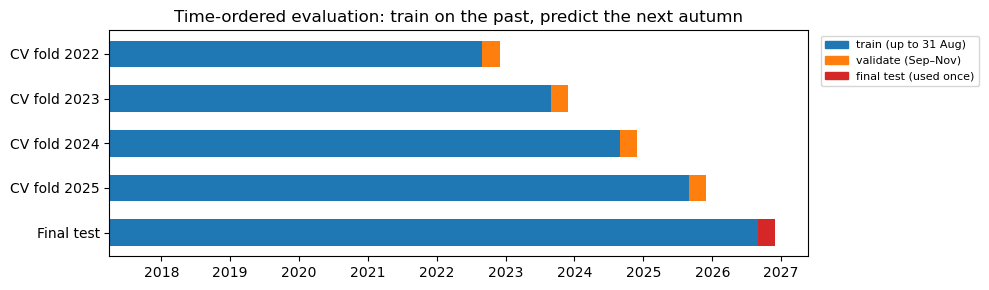

In [23]:

start = pd.Timestamp("2017-04-01")
rows = [(f"CV fold {y}", f"{y}-08-31", f"{y}-11-30") for y in cv_years] + [("Final test", cutoff_final, end_final)]

fig, ax = plt.subplots(figsize = (10, 3))

for i, (name, cut, end) in enumerate(rows):
    cut, end = pd.Timestamp(cut), pd.Timestamp(end)
    ax.barh(i, cut - start, left = start, color = "tab:blue", height = 0.6)  # training part
    ax.barh(i, end - cut, left = cut, height = 0.6,                          # predicted autumn
            color = "tab:red" if name == "Final test" else "tab:orange")

ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(handles = [Patch(color = "tab:blue",   label = "train (up to 31 Aug)"),
                     Patch(color = "tab:orange", label = "validate (Sep–Nov)"),
                     Patch(color = "tab:red",    label = "final test (used once)")],
          loc = "upper left", bbox_to_anchor = (1.01, 1), fontsize = 8)

ax.set_title("Time-ordered evaluation: train on the past, predict the next autumn")
plt.tight_layout(); plt.show()

In [24]:

# results table 
res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])

# best setting of each model 
best = res.loc[res.groupby("model")["cv_mean"].idxmin()].copy()
best = best.sort_values("cv_mean").reset_index(drop = True)
best[["model", "param", "cv_mean", "cv_sd"]].round(3)

,model,param,cv_mean,cv_sd
0,SparseKernelMachine,"(0.0001, 0.0003)",1.068,0.183
1,KernelRidge,"(10, 0.01)",1.069,0.184
2,Elastic net,0.1,1.073,0.186
3,Polynomial+Ridge,"(10000.0, 1)",1.075,0.172
4,Lasso,0.1,1.076,0.191
5,Ridge,1000.0,1.076,0.172
6,Linear Regression,None,1.076,0.172
7,Polynomial,1,1.076,0.172
8,Baseline model,None,1.084,0.180


In [25]:
en_scores = cv_score(make_pipeline(StandardScaler(), ElasticNet(alpha = 0.1, l1_ratio = 0.5)),
                     river_long2, cv_years, feats, fold_fn = fold_A)

folds_table = pd.DataFrame({"Seasonal LR":   base,
                            "Linear + clim": lr_score,
                            "Elastic net":   en_scores,
                            "Kernel ridge":  krr_scores[10, 0.01],
                            "Sparse kernel": sk_scores[1e-4, 0.0003]},
                           index = cv_years).round(3)

# paired differences against linear + clim (negative = better than LC in that fold)
ref = folds_table["Linear + clim"]
for col in ["Seasonal LR", "Elastic net", "Kernel ridge", "Sparse kernel"]:
    folds_table[f"{col} − LC"] = (folds_table[col] - ref).round(3)
folds_table

,Seasonal LR,Linear + clim,Elastic net,Kernel ridge,Sparse kernel,Seasonal LR − LC,Elastic net − LC,Kernel ridge − LC,Sparse kernel − LC
2022,1.104,1.070,1.086,1.080,1.080,0.034,0.016,0.010,0.010
2023,1.322,1.317,1.322,1.316,1.313,0.005,0.005,-0.001,-0.004
2024,0.895,0.919,0.883,0.880,0.880,-0.024,-0.036,-0.039,-0.039
2025,1.015,0.999,1.002,0.999,0.999,0.016,0.003,0.000,0.000


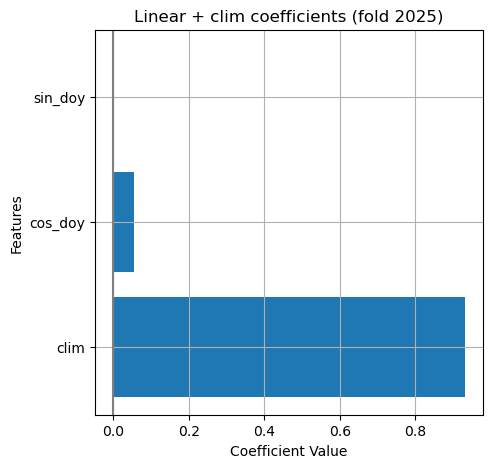

,feature,coef
3,clim,0.931291
2,cos_doy,0.054644
1,sin_doy,-0.000942


In [26]:
train_25, val_25 = folds_A[2025]
linear_clim_25 = LinearRegression().fit(train_25[feats], train_25["z"])
get_coefs(linear_clim_25, plot = True, figtitle = "Linear + clim coefficients (fold 2025)", intercept = False)

In [27]:
seasonal_25 = LinearRegression().fit(train_25[season_cols], train_25["z"])
get_coefs(seasonal_25)

,feature,coef
2,cos_doy,0.651857
0,intercept,0.035982
1,sin_doy,-0.055745


In [28]:
train26, test26 = make_fold_clim(river_long2, 2026)
final_clim = LinearRegression().fit(train26[feats], train26["z"])
seasonal = LinearRegression().fit(train26[season_cols], train26["z"])

test_results = pd.DataFrame([
    score("Seasonal LR", seasonal.predict(test26[season_cols]), test26["z"], test26),
    score("Linear + clim (final)", final_clim.predict(test26[feats]), test26["z"], test26),
]).set_index("model").round(3)
test_results

,RMSE (z),RMSE (m),MAE (m)
model,,,
Seasonal LR,0.955,0.190,0.135
Linear + clim (final),0.927,0.188,0.128


In [29]:
test_rows = test26.copy()
test_rows["pred_z"]  = final_clim.predict(test26[feats])
test_rows["pred_m"]  = test_rows["pred_z"] * test_rows["sta_std"] + test_rows["sta_mean"]   # back to metres
test_rows["seas_m"]  = seasonal.predict(test26[season_cols]) * test_rows["sta_std"] + test_rows["sta_mean"]
test_rows["err_z"]   = (test_rows["z"] - test_rows["pred_z"]).abs()      # for ranking (fair across river sizes)
test_rows["abs_err"] = (test_rows["avg"] - test_rows["pred_m"]).abs()    # in metres, for the reader

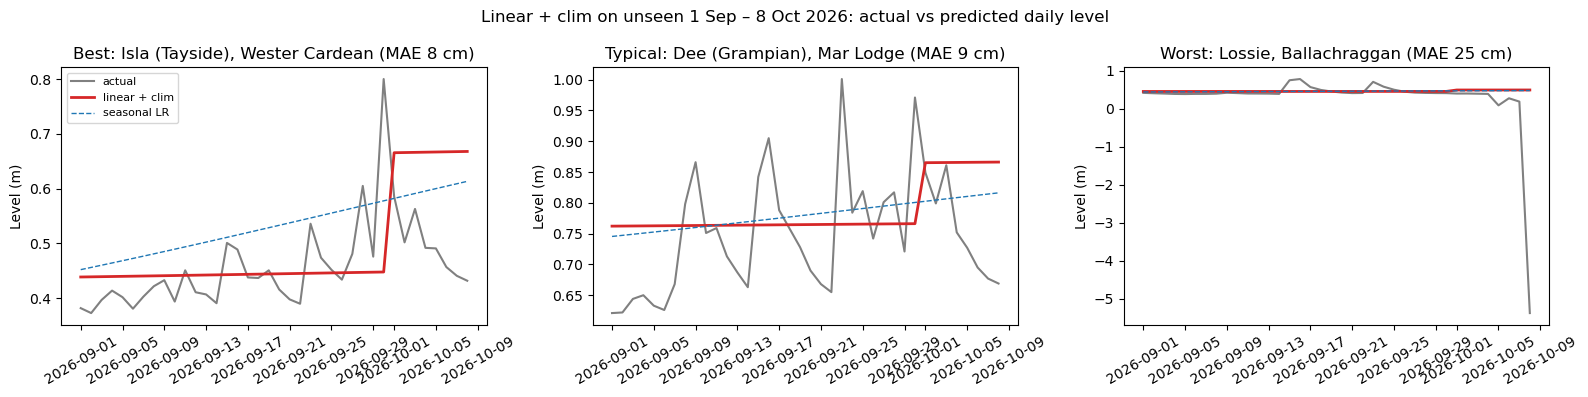

In [30]:
sta_err = test_rows.groupby("Observation_ID", observed = True)["err_z"].mean().sort_values()
picks = {"Best": sta_err.index[0], "Typical": sta_err.index[len(sta_err) // 2], "Worst": sta_err.index[-1]}

fig, axes = plt.subplots(1, 3, figsize = (16, 4))
for ax, (label, sta_id) in zip(axes, picks.items()):
    sta = test_rows[test_rows["Observation_ID"] == sta_id].sort_values("date")
    mae_cm = sta["abs_err"].mean() * 100
    ax.plot(sta["date"], sta["avg"],    color = "grey",     lw = 1.5, label = "actual")
    ax.plot(sta["date"], sta["pred_m"], color = "tab:red",  lw = 2,   label = "linear + clim")
    ax.plot(sta["date"], sta["seas_m"], color = "tab:blue", lw = 1, ls = "--", label = "seasonal LR")
    ax.set_title(f"{label}: {sta['Station_Name'].iloc[0]} (MAE {mae_cm:.0f} cm)")
    ax.set_ylabel("Level (m)")
    ax.tick_params(axis = "x", rotation = 30)
axes[0].legend(fontsize = 8)
fig.suptitle("Linear + clim on unseen 1 Sep – 8 Oct 2026: actual vs predicted daily level")
plt.tight_layout(); plt.show()

In [31]:
month = test_rows["date"].dt.month
mae_month = pd.DataFrame({
    "Linear + clim MAE (cm)":   test_rows["abs_err"].groupby(month).mean() * 100,
    "Seasonal LR MAE (cm)": (test_rows["avg"] - test_rows["seas_m"]).abs().groupby(month).mean() * 100,
}).round(1)
mae_month.index = mae_month.index.map({9: "Sep", 10: "Oct", 11: "Nov"})
mae_month

,Linear + clim MAE (cm),Seasonal LR MAE (cm)
date,,
Sep,12.3,13.7
Oct,14.8,12.7
